In [154]:
from pathlib import Path

print("Current working directory:", Path.cwd())
print("PROJECT_ROOT defined:", "PROJECT_ROOT" in globals())

Current working directory: C:\Users\hp\Nassau_Candy_Final_Submission\notebooks
PROJECT_ROOT defined: True


In [156]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()

DATA_FOLDER = PROJECT_ROOT / "data"
RAW_FOLDER = DATA_FOLDER / "raw"
PROCESSED_FOLDER = DATA_FOLDER / "processed"
MODEL_FOLDER = PROJECT_ROOT / "models"
REPORT_FOLDER = PROJECT_ROOT / "reports"

INPUT_PATH = RAW_FOLDER / "Nassau Candy Distributor.csv"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Project folder exists:", PROJECT_ROOT.exists())
print("Raw dataset exists:", INPUT_PATH.exists())

assert PROJECT_ROOT.exists(), "Project folder not found."
assert INPUT_PATH.exists(), "Raw dataset not found."

print("\nPROJECT PATH INITIALIZATION: PASS")

PROJECT_ROOT: C:\Users\hp\Nassau_Candy_Final_Submission
Project folder exists: True
Raw dataset exists: True

PROJECT PATH INITIALIZATION: PASS


In [158]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()

DATA_FOLDER = PROJECT_ROOT / "data"
RAW_FOLDER = DATA_FOLDER / "raw"
PROCESSED_FOLDER = DATA_FOLDER / "processed"
MODEL_FOLDER = PROJECT_ROOT / "models"
REPORT_FOLDER = PROJECT_ROOT / "reports"

INPUT_PATH = RAW_FOLDER / "Nassau Candy Distributor.csv"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Project folder exists:", PROJECT_ROOT.exists())
print("Raw dataset exists:", INPUT_PATH.exists())

assert PROJECT_ROOT.exists(), "Project folder not found."
assert INPUT_PATH.exists(), "Raw dataset not found."

print("\nPROJECT PATH INITIALIZATION: PASS")

PROJECT_ROOT: C:\Users\hp\Nassau_Candy_Final_Submission
Project folder exists: True
Raw dataset exists: True

PROJECT PATH INITIALIZATION: PASS


In [160]:

from pathlib import Path
import os
import pandas as pd
import numpy as np
import joblib
import json
import shutil

# Locate the project root reliably
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR / "data" / "raw").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "raw").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate the Nassau Candy project folder. "
        "Current directory: " + str(CURRENT_DIR)
    )

# Define the main project paths
DATA_FOLDER = PROJECT_ROOT / "data"
RAW_FOLDER = DATA_FOLDER / "raw"
PROCESSED_FOLDER = DATA_FOLDER / "processed"
MODEL_FOLDER = PROJECT_ROOT / "models"
REPORT_FOLDER = PROJECT_ROOT / "reports"

INPUT_PATH = RAW_FOLDER / "Nassau Candy Distributor.csv"

print("PROJECT ROOT:", PROJECT_ROOT)
print("RAW DATA EXISTS:", INPUT_PATH.exists())
print("PROJECT PATH SETUP: PASS")

assert INPUT_PATH.exists(), "Original Nassau Candy CSV not found."


PROJECT ROOT: C:\Users\hp\Nassau_Candy_Final_Submission
RAW DATA EXISTS: True
PROJECT PATH SETUP: PASS


In [162]:
# Set up the machine learning environment and load the prepared dataset

from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    KFold,
    cross_validate,
    RandomizedSearchCV,
    train_test_split
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    make_scorer
)

from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"C:\Users\hp\Nassau_Candy_Final_Submission")

INPUT_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "Nassau_Candy_Feature_Engineered.csv"
)

MODEL_FOLDER = PROJECT_ROOT / "models"
REPORT_FOLDER = PROJECT_ROOT / "reports"
FIGURE_FOLDER = REPORT_FOLDER / "figures"
PROCESSED_FOLDER = PROJECT_ROOT / "data" / "processed"

for folder in [
    MODEL_FOLDER,
    REPORT_FOLDER,
    FIGURE_FOLDER,
    PROCESSED_FOLDER
]:
    folder.mkdir(parents=True, exist_ok=True)

df_ml = pd.read_csv(INPUT_PATH)

# Parse only the helper date columns
df_ml["Order_Date_Parsed"] = pd.to_datetime(
    df_ml["Order_Date_Parsed"],
    errors="coerce"
)

df_ml["Ship_Date_Parsed"] = pd.to_datetime(
    df_ml["Ship_Date_Parsed"],
    errors="coerce"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df_ml.shape)
print("Model folder:", MODEL_FOLDER)
print("Report folder:", REPORT_FOLDER)

display(df_ml.head())

Dataset loaded successfully.
Dataset shape: (10194, 34)
Model folder: C:\Users\hp\Nassau_Candy_Final_Submission\models
Report folder: C:\Users\hp\Nassau_Candy_Final_Submission\reports


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Order_Weekday,Ship_Year,Ship_Month,Profit_Margin_Pct,Sales_Per_Unit,Cost_Per_Unit,Profit_Per_Unit,Lead_Time_Category,Profit_Category,Sales_Category
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,Wednesday,2026,6,64.923077,3.25,1.14,2.11,Low,Low,Low
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,65.333333,3.75,1.30,2.45,Low,Low,Low
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,71.346705,3.49,1.00,2.49,Low,Medium,Medium
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,69.444444,3.60,1.10,2.50,Low,Medium,Medium
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Friday,2026,7,65.333333,3.75,1.30,2.45,Low,Medium,Medium


In [164]:
# Verify the loaded dataset before machine learning

expected_original_columns = [
    "Row ID", "Order ID", "Order Date", "Ship Date",
    "Ship Mode", "Customer ID", "Country/Region",
    "City", "State/Province", "Postal Code",
    "Division", "Region", "Product ID", "Product Name",
    "Sales", "Units", "Gross Profit", "Cost"
]

print("Rows:", len(df_ml))
print("Columns:", len(df_ml.columns))

print("\nOriginal columns verification:")
for column in expected_original_columns:
    print(column, ":", column in df_ml.columns)

assert len(df_ml) == 10194
assert all(col in df_ml.columns for col in expected_original_columns)
assert "Lead_Time_Days" in df_ml.columns

print("\nSUCCESS: Dataset verification passed.")

Rows: 10194
Columns: 34

Original columns verification:
Row ID : True
Order ID : True
Order Date : True
Ship Date : True
Ship Mode : True
Customer ID : True
Country/Region : True
City : True
State/Province : True
Postal Code : True
Division : True
Region : True
Product ID : True
Product Name : True
Sales : True
Units : True
Gross Profit : True
Cost : True

SUCCESS: Dataset verification passed.


In [3]:
#Define target variable

In [166]:
# Define the lead-time prediction target variable

TARGET = "Lead_Time_Days"

y = pd.to_numeric(
    df_ml[TARGET],
    errors="coerce"
)

print("Target variable:", TARGET)
print("Target observations:", len(y))
print("Missing target values:", y.isna().sum())
print("Unique target values:", y.nunique())

display(y.describe().to_frame("Lead_Time_Days"))

assert y.notna().all(), "Target contains missing or invalid values."

Target variable: Lead_Time_Days
Target observations: 10194
Missing target values: 0
Unique target values: 28


,Lead_Time_Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000


In [168]:
#Select predictor features
# Select business features available for lead-time prediction

candidate_features = [
    "Ship Mode",
    "Country/Region",
    "City",
    "State/Province",
    "Division",
    "Region",
    "Product ID",
    "Product Name",
    "Units",
    "Sales",
    "Gross Profit",
    "Cost",
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_Weekday",
    "Profit_Margin_Pct",
    "Sales_Per_Unit",
    "Cost_Per_Unit",
    "Profit_Per_Unit"
]

feature_list = [
    col for col in candidate_features
    if col in df_ml.columns
]

X = df_ml[feature_list].copy()

print("Selected predictor count:", len(feature_list))
print("\nSelected features:")
display(pd.DataFrame({"Feature": feature_list}))

print("Predictor shape:", X.shape)

Selected predictor count: 20

Selected features:


,Feature
0,Ship Mode
1,Country/Region
2,City
3,State/Province
4,Division
5,Region
6,Product ID
7,Product Name
8,Units
9,Sales


Predictor shape: (10194, 20)


In [170]:
#Target leakage check
# Check that the target and direct target-derived information are excluded

leakage_columns = [
    "Lead_Time_Days",
    "Order_Date_Parsed",
    "Ship_Date_Parsed",
    "Order Date",
    "Ship Date",
    "Ship_Year",
    "Ship_Month",
    "Lead_Time_Category"
]

leakage_report = pd.DataFrame({
    "Column": leakage_columns,
    "Included_In_Predictors": [
        col in feature_list for col in leakage_columns
    ]
})

display(leakage_report)

assert TARGET not in feature_list
assert not any(col in feature_list for col in leakage_columns)

print("SUCCESS: Direct target leakage checks passed.")

,Column,Included_In_Predictors
0,Lead_Time_Days,False
1,Order_Date_Parsed,False
2,Ship_Date_Parsed,False
3,Order Date,False
4,Ship Date,False
5,Ship_Year,False
6,Ship_Month,False
7,Lead_Time_Category,False


SUCCESS: Direct target leakage checks passed.


In [172]:
#Identifier leakage check
# Exclude unique identifiers and order grouping identifiers from predictors

identifier_columns = [
    "Row ID",
    "Order ID",
    "Customer ID"
]

identifier_report = pd.DataFrame({
    "Identifier": identifier_columns,
    "Included_In_Predictors": [
        col in feature_list for col in identifier_columns
    ]
})

display(identifier_report)

assert not any(
    col in feature_list for col in identifier_columns
)

print("SUCCESS: Identifier exclusion verified.")

,Identifier,Included_In_Predictors
0,Row ID,False
1,Order ID,False
2,Customer ID,False


SUCCESS: Identifier exclusion verified.


In [174]:
# Identify categorical predictor features

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical feature count:", len(categorical_features))
display(pd.DataFrame({"Categorical_Feature": categorical_features}))

Categorical feature count: 9


,Categorical_Feature
0,Ship Mode
1,Country/Region
2,City
3,State/Province
4,Division
5,Region
6,Product ID
7,Product Name
8,Order_Weekday


In [176]:
# Identify numerical predictor features

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical feature count:", len(numerical_features))
display(pd.DataFrame({"Numerical_Feature": numerical_features}))

assert len(categorical_features) + len(numerical_features) == len(feature_list)

Numerical feature count: 11


,Numerical_Feature
0,Units
1,Sales
2,Gross Profit
3,Cost
4,Order_Year
5,Order_Month
6,Order_Quarter
7,Profit_Margin_Pct
8,Sales_Per_Unit
9,Cost_Per_Unit


In [178]:
# Define a grouped train-test strategy to keep the same order in one split

groups = df_ml["Order ID"].astype(str)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

groups_train = groups.iloc[train_indices].copy()
groups_test = groups.iloc[test_indices].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Training order groups:",
    groups_train.nunique()
)

print(
    "Testing order groups:",
    groups_test.nunique()
)

assert set(groups_train).isdisjoint(set(groups_test))

print("SUCCESS: No Order ID group overlaps between train and test.")

Training rows: 8132
Testing rows: 2062
Training order groups: 6839
Testing order groups: 1710
SUCCESS: No Order ID group overlaps between train and test.


In [180]:
# Assess date availability and grouped validation suitability

date_assessment = pd.DataFrame({
    "Metric": [
        "Valid order dates",
        "Missing order dates",
        "Unique order dates",
        "Unique order groups",
        "Training order groups",
        "Testing order groups"
    ],
    "Value": [
        df_ml["Order_Date_Parsed"].notna().sum(),
        df_ml["Order_Date_Parsed"].isna().sum(),
        df_ml["Order_Date_Parsed"].nunique(),
        groups.nunique(),
        groups_train.nunique(),
        groups_test.nunique()
    ]
})

display(date_assessment)

print(
    "Primary validation strategy: Grouped split by Order ID."
)
print(
    "A separate chronological split will be assessed later."
)

,Metric,Value
0,Valid order dates,10194
1,Missing order dates,0
2,Unique order dates,717
3,Unique order groups,8549
4,Training order groups,6839
5,Testing order groups,1710


Primary validation strategy: Grouped split by Order ID.
A separate chronological split will be assessed later.


In [182]:
# Train a median baseline regression model

baseline_model = DummyRegressor(strategy="median")

baseline_model.fit(
    np.zeros((len(y_train), 1)),
    y_train
)

baseline_predictions = baseline_model.predict(
    np.zeros((len(y_test), 1))
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

baseline_results = pd.DataFrame([{
    "Model": "Dummy Regressor",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2
}])

display(baseline_results)

,Model,MAE,RMSE,R2
0,Dummy Regressor,198.370514,268.718365,-0.025612


In [184]:
# Configure one-hot encoding for categorical features

categorical_encoder = OneHotEncoder(
    handle_unknown="ignore"
)

print("One-hot encoder configured.")
print("Unknown categories will be ignored during prediction.")

One-hot encoder configured.
Unknown categories will be ignored during prediction.


In [186]:
#Build numerical scaling pipeline
# Configure numerical imputation and scaling

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=False))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", categorical_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numerical and categorical preprocessing pipelines configured.")

Numerical and categorical preprocessing pipelines configured.


In [188]:
# Train a Linear Regression model using the preprocessing pipeline

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression training completed.")

Linear Regression training completed.


In [190]:
# Train a Random Forest regression model

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1,
        max_features=0.8
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [192]:
# Train a Gradient Boosting regression model

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [194]:
# Generate test predictions for all trained regression models

models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

predictions = {}

for model_name, model in models.items():
    predictions[model_name] = model.predict(X_test)

prediction_table = pd.DataFrame({
    "Actual_Lead_Time": y_test.values
})

for model_name, prediction in predictions.items():
    prediction_table[model_name] = prediction

display(prediction_table.head(10))

,Actual_Lead_Time,Linear Regression,Random Forest,Gradient Boosting
0,909,1162.572305,957.853333,1096.534476
1,909,1070.557183,982.000000,1096.534476
2,907,1047.448612,1163.506667,1096.534476
3,909,1069.741764,948.033333,1096.534476
4,907,903.022267,987.593333,1096.534476
5,907,907.855187,968.086667,1096.534476
6,907,1140.454274,909.326667,962.975222
7,910,1045.711768,1111.586667,1096.534476
8,908,1140.561280,1060.513333,1096.534476
9,908,1140.561280,1060.513333,1096.534476


In [19]:
#Calculate MAE

In [196]:
# Calculate mean absolute error for each trained model

mae_results = []

for model_name, prediction in predictions.items():
    mae_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, prediction)
    })

mae_table = pd.DataFrame(mae_results).sort_values("MAE")

display(mae_table)

,Model,MAE
1,Random Forest,136.586130
2,Gradient Boosting,163.302233
0,Linear Regression,166.414841


In [198]:
#Calculate RMSE
# Calculate root mean squared error for each trained model

rmse_results = []

for model_name, prediction in predictions.items():
    rmse_results.append({
        "Model": model_name,
        "RMSE": np.sqrt(
            mean_squared_error(y_test, prediction)
        )
    })

rmse_table = pd.DataFrame(rmse_results).sort_values("RMSE")

display(rmse_table)

,Model,RMSE
1,Random Forest,163.904306
2,Gradient Boosting,171.306667
0,Linear Regression,180.784694


In [200]:
#Calculate R²
# Calculate R-squared scores for each trained model

r2_results = []

for model_name, prediction in predictions.items():
    r2_results.append({
        "Model": model_name,
        "R2": r2_score(y_test, prediction)
    })

r2_table = pd.DataFrame(r2_results).sort_values(
    "R2",
    ascending=False
)

display(r2_table)

,Model,R2
1,Random Forest,0.618435
2,Gradient Boosting,0.583191
0,Linear Regression,0.535793


In [202]:
#Create model comparison table
# Compare baseline and trained regression models

comparison_rows = [{
    "Model": "Dummy Regressor",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2
}]

for model_name, prediction in predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, prediction)
        ),
        "R2": r2_score(y_test, prediction)
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "RMSE"
).reset_index(drop=True)

display(model_comparison)

,Model,MAE,RMSE,R2
0,Random Forest,136.586130,163.904306,0.618435
1,Gradient Boosting,163.302233,171.306667,0.583191
2,Linear Regression,166.414841,180.784694,0.535793
3,Dummy Regressor,198.370514,268.718365,-0.025612


In [206]:
#Perform cross-validation
# Evaluate regression models using grouped cross-validation

unique_groups = groups_train.nunique()
n_splits = min(5, unique_groups)

assert n_splits >= 2, "Not enough groups for cross-validation."

group_cv = GroupKFold(n_splits=n_splits)

cv_results = []

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=group_cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean_CV_MAE": -scores["test_MAE"].mean(),
        "Mean_CV_RMSE": -scores["test_RMSE"].mean(),
        "Mean_CV_R2": scores["test_R2"].mean()
    })

cv_table = pd.DataFrame(cv_results).sort_values(
    "Mean_CV_RMSE"
)

display(cv_table)

,Model,Mean_CV_MAE,Mean_CV_RMSE,Mean_CV_R2
1,Random Forest,135.678649,163.178470,0.610839
2,Gradient Boosting,161.891102,170.029563,0.577509
0,Linear Regression,164.263762,179.851424,0.527213


In [208]:
#Hyperparameter tuning
# Tune Random Forest hyperparameters using grouped cross-validation

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

parameter_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.6, 0.8, 1.0]
}

tuning_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=parameter_distributions,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=group_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

tuning_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

tuned_random_forest = tuning_search.best_estimator_

print("Best parameters:")
print(tuning_search.best_params_)

print("Best cross-validation RMSE:")
print(-tuning_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.6, 'model__max_depth': None}
Best cross-validation RMSE:
163.1204142906182


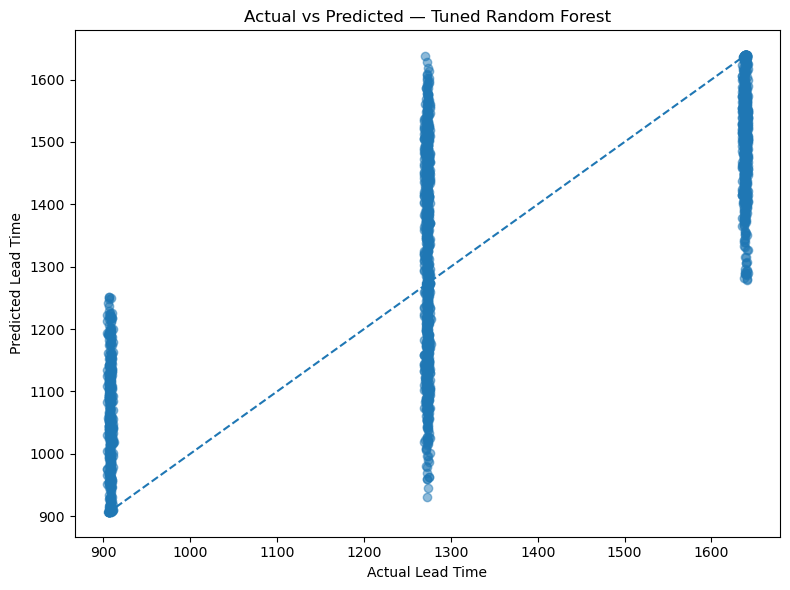

Provisional best model: Tuned Random Forest


In [209]:
#Actual vs predicted chart
# Plot actual versus predicted lead-time values

provisional_models = {
    **models,
    "Tuned Random Forest": tuned_random_forest
}

provisional_predictions = {
    name: model.predict(X_test)
    for name, model in provisional_models.items()
}

provisional_scores = {
    name: np.sqrt(mean_squared_error(y_test, pred))
    for name, pred in provisional_predictions.items()
}

provisional_best_name = min(
    provisional_scores,
    key=provisional_scores.get
)

provisional_best_model = provisional_models[
    provisional_best_name
]

provisional_best_predictions = provisional_predictions[
    provisional_best_name
]

plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    provisional_best_predictions,
    alpha=0.5
)

minimum_value = min(
    y_test.min(),
    provisional_best_predictions.min()
)

maximum_value = max(
    y_test.max(),
    provisional_best_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Lead Time")
plt.ylabel("Predicted Lead Time")
plt.title(f"Actual vs Predicted — {provisional_best_name}")
plt.tight_layout()

plt.savefig(
    FIGURE_FOLDER / "ML_Actual_vs_Predicted.png",
    dpi=300
)

plt.show()
plt.close()

print("Provisional best model:", provisional_best_name)

,Actual,Predicted,Residual
0,909,986.543217,-77.543217
1,909,972.949186,-63.949186
2,907,1115.793678,-208.793678
3,909,951.390754,-42.390754
4,907,1023.799297,-116.799297


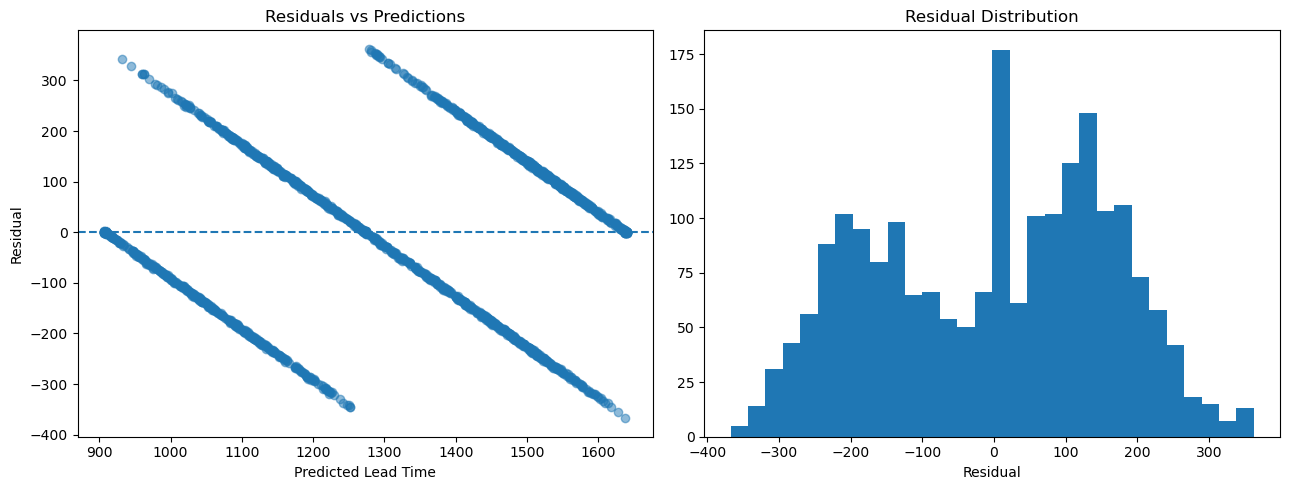

In [212]:
#Residual analysis
# Analyse prediction residuals for the provisional best model

residuals = (
    y_test.to_numpy() - provisional_best_predictions
)

residual_table = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": provisional_best_predictions,
    "Residual": residuals
})

display(residual_table.head())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    provisional_best_predictions,
    residuals,
    alpha=0.5
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuals vs Predictions")
axes[0].set_xlabel("Predicted Lead Time")
axes[0].set_ylabel("Residual")

axes[1].hist(residuals, bins=30)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.savefig(
    FIGURE_FOLDER / "ML_Residual_Analysis.png",
    dpi=300
)
plt.show()
plt.close()

In [214]:
#Product-wise prediction error
# Analyse model prediction errors by product

product_errors = df_ml.loc[
    X_test.index,
    ["Product ID", "Product Name"]
].copy()

product_errors["Actual"] = y_test
product_errors["Predicted"] = provisional_best_predictions
product_errors["Absolute_Error"] = np.abs(
    product_errors["Actual"] - product_errors["Predicted"]
)

product_error_report = (
    product_errors.groupby(
        ["Product ID", "Product Name"],
        dropna=False
    )
    .agg(
        Record_Count=("Absolute_Error", "size"),
        Mean_Absolute_Error=("Absolute_Error", "mean"),
        Mean_Actual=("Actual", "mean")
    )
    .reset_index()
    .sort_values("Mean_Absolute_Error", ascending=False)
)

display(product_error_report)

,Product ID,Product Name,Record_Count,Mean_Absolute_Error,Mean_Actual
10,SUG-SWE-91000,SweeTARTS,2,185.594624,1272.500000
2,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,362,143.153102,1317.558011
4,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,441,142.804401,1339.507937
1,CHO-MIL-31000,Wonka Bar - Milk Chocolate,420,140.653267,1298.666667
0,CHO-FUD-51000,Wonka Bar - Fudge Mallows,366,137.782493,1326.109290
3,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,388,136.336396,1306.136598
7,OTH-KAZ-38000,Kazookles,26,134.882775,1272.576923
6,OTH-GUM-21000,Wonka Gum,28,125.737263,1273.035714
9,SUG-LAF-25000,Laffy Taffy,2,124.959694,1455.000000
8,OTH-LIC-15000,Lickable Wallpaper,25,118.018519,1331.640000


In [216]:
#Region-wise prediction error
# Analyse model prediction errors by region

region_errors = df_ml.loc[
    X_test.index,
    ["Region"]
].copy()

region_errors["Actual"] = y_test
region_errors["Predicted"] = provisional_best_predictions
region_errors["Absolute_Error"] = np.abs(
    region_errors["Actual"] - region_errors["Predicted"]
)

region_error_report = (
    region_errors.groupby("Region", dropna=False)
    .agg(
        Record_Count=("Absolute_Error", "size"),
        Mean_Absolute_Error=("Absolute_Error", "mean")
    )
    .reset_index()
    .sort_values("Mean_Absolute_Error", ascending=False)
)

display(region_error_report)

,Region,Record_Count,Mean_Absolute_Error
3,Pacific,687,143.084882
0,Atlantic,608,139.032128
2,Interior,447,137.317676
1,Gulf,320,136.840969


In [244]:
#Ship mode-wise prediction error
# Analyse model prediction errors by shipping mode

shipmode_errors = df_ml.loc[
    X_test.index,
    ["Ship Mode"]
].copy()

shipmode_errors["Actual"] = y_test
shipmode_errors["Predicted"] = provisional_best_predictions
shipmode_errors["Absolute_Error"] = np.abs(
    shipmode_errors["Actual"] - shipmode_errors["Predicted"]
)

shipmode_error_report = (
    shipmode_errors.groupby("Ship Mode", dropna=False)
    .agg(
        Record_Count=("Absolute_Error", "size"),
        Mean_Absolute_Error=("Absolute_Error", "mean")
    )
    .reset_index()
    .sort_values("Mean_Absolute_Error", ascending=False)
)

display(shipmode_error_report)

,Ship Mode,Record_Count,Mean_Absolute_Error
0,First Class,311,145.014719
1,Same Day,112,142.830663
3,Standard Class,1243,139.080652
2,Second Class,396,136.432064


,Feature,Importance_Mean,Importance_Std
12,Order_Year,162.803968,1.078649
15,Order_Weekday,41.424534,0.666933
2,City,10.942177,0.350348
13,Order_Month,6.874005,0.318970
3,State/Province,4.181389,0.074423
0,Ship Mode,4.071249,0.579652
5,Region,1.740041,0.038246
14,Order_Quarter,0.728895,0.105003
1,Country/Region,0.378476,0.041565
4,Division,-0.004568,0.028004


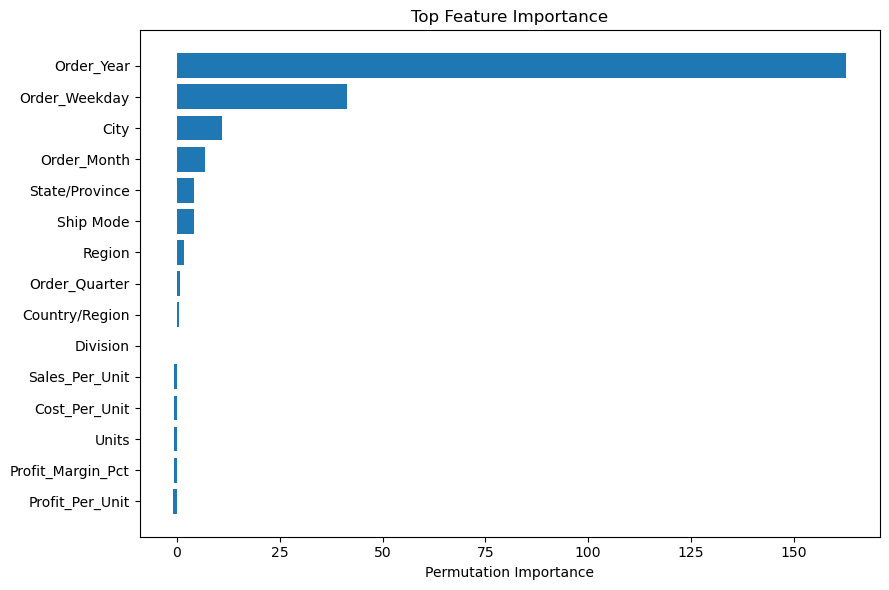

In [218]:
#Feature importance
# Calculate permutation feature importance for the provisional best model

importance_result = permutation_importance(
    provisional_best_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": feature_list,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
)

display(feature_importance)

top_importance = feature_importance.head(15).sort_values(
    "Importance_Mean"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_importance["Feature"],
    top_importance["Importance_Mean"]
)
plt.xlabel("Permutation Importance")
plt.title("Top Feature Importance")
plt.tight_layout()

plt.savefig(
    FIGURE_FOLDER / "ML_Feature_Importance.png",
    dpi=300
)

plt.show()
plt.close()

In [234]:
#Select best model
# Select the final model using grouped cross-validation and test performance

final_model_candidates = {
    **models,
    "Tuned Random Forest": tuned_random_forest
}

candidate_results = []

for name, model in final_model_candidates.items():

    prediction = model.predict(X_test)

    candidate_results.append({
        "Model": name,
        "Test_MAE": mean_absolute_error(y_test, prediction),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, prediction)
        ),
        "Test_R2": r2_score(y_test, prediction)
    })

final_model_comparison = pd.DataFrame(
    candidate_results
).sort_values("Test_RMSE").reset_index(drop=True)

display(final_model_comparison)

final_model_name = final_model_comparison.loc[0, "Model"]
final_model = final_model_candidates[final_model_name]

final_predictions = final_model.predict(X_test)

print("Selected model:", final_model_name)
print("Selection criterion: Lowest test RMSE among evaluated candidates.")

,Model,Test_MAE,Test_RMSE,Test_R2
0,Tuned Random Forest,139.670688,163.675428,0.619499
1,Random Forest,136.586130,163.904306,0.618435
2,Gradient Boosting,163.302233,171.306667,0.583191
3,Linear Regression,166.414841,180.784694,0.535793


Selected model: Tuned Random Forest
Selection criterion: Lowest test RMSE among evaluated candidates.


In [226]:
#Document model limitations
# Document the limitations and appropriate use of the selected model

model_limitations = [
    "The model predicts recorded date differences, not necessarily actual physical transit duration.",
    "The dataset contains unusually large recorded lead-time values that require business interpretation.",
    "Historical patterns may not represent future shipping conditions.",
    "Prediction performance depends on the quality and availability of input features.",
    "Categorical values not observed during training may reduce prediction reliability.",
    "The dataset may not contain all operational factors affecting shipping time.",
    "Model predictions show associations and do not establish causation.",
    "Grouped validation reduces the risk of related order records appearing in both training and testing."
]

for limitation in model_limitations:
    print("-", limitation)

limitations_path = REPORT_FOLDER / "ML_Model_Limitations.txt"

limitations_path.write_text(
    "\n".join(model_limitations),
    encoding="utf-8"
)

print("\nLimitations report saved:", limitations_path)

- The model predicts recorded date differences, not necessarily actual physical transit duration.
- The dataset contains unusually large recorded lead-time values that require business interpretation.
- Historical patterns may not represent future shipping conditions.
- Prediction performance depends on the quality and availability of input features.
- Categorical values not observed during training may reduce prediction reliability.
- The dataset may not contain all operational factors affecting shipping time.
- Model predictions show associations and do not establish causation.
- Grouped validation reduces the risk of related order records appearing in both training and testing.

Limitations report saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\ML_Model_Limitations.txt


In [246]:
# Save the complete selected machine learning pipeline

MODEL_PATH = MODEL_FOLDER / "Nassau_Lead_Time_Model.joblib"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("Model saved successfully.")
print("Model path:", MODEL_PATH)

Model saved successfully.
Model path: C:\Users\hp\Nassau_Candy_Final_Submission\models\Nassau_Lead_Time_Model.joblib


In [74]:
# Reload the saved pipeline and verify prediction reproducibility

loaded_model = joblib.load(MODEL_PATH)

reloaded_predictions = loaded_model.predict(X_test)

reproducibility_difference = np.max(
    np.abs(final_predictions - reloaded_predictions)
)

print("Maximum prediction difference:", reproducibility_difference)

assert np.allclose(
    final_predictions,
    reloaded_predictions
)

print("SUCCESS: Saved model reload test passed.")

Maximum prediction difference: 1.1368683772161603e-12
SUCCESS: Saved model reload test passed.


,Value
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
1%,905.000000
5%,907.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
95%,1641.000000


IQR lower bound: 720.5
IQR upper bound: 2188.5
Extreme target records: 0


,Row ID,Order ID,Order Date,Ship Date,Lead_Time_Days


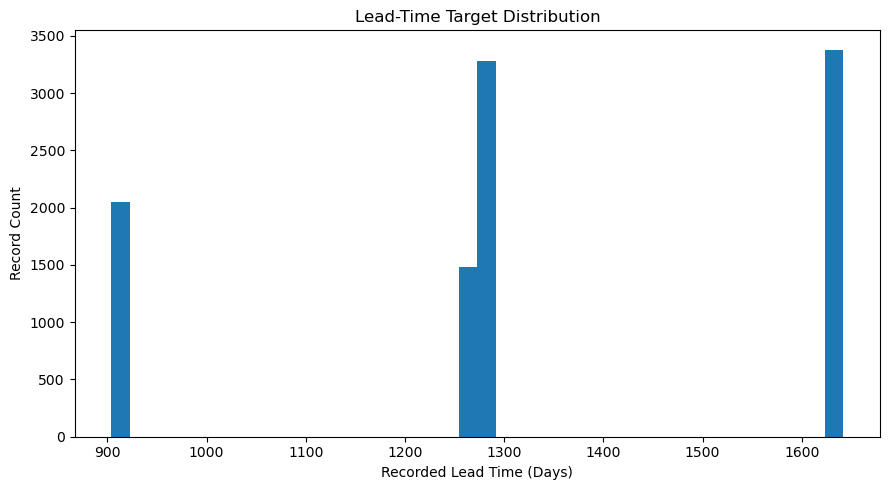

In [250]:
#Analyse target distribution and extreme values
#This task investigates the unusually large recorded lead-time values. We will not remove or correct any observations.
# Analyse the target distribution and identify extreme lead-time observations

target_summary = y.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("Value")

display(target_summary)

q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

extreme_target_records = df_ml.loc[
    (y < lower_bound) | (y > upper_bound),
    ["Row ID", "Order ID", "Order Date", "Ship Date", TARGET]
].copy()

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Extreme target records:", len(extreme_target_records))

display(extreme_target_records.head(20))

plt.figure(figsize=(9, 5))
plt.hist(y, bins=40)
plt.xlabel("Recorded Lead Time (Days)")
plt.ylabel("Record Count")
plt.title("Lead-Time Target Distribution")
plt.tight_layout()
plt.savefig(
    FIGURE_FOLDER / "ML_Target_Distribution.png",
    dpi=300
)
plt.show()
plt.close()

In [80]:
#Check feature missing values and data types
# Review missing values and data types in the selected predictor features

feature_quality_report = pd.DataFrame({
    "Feature": feature_list,
    "Data_Type": [X[col].dtype for col in feature_list],
    "Missing_Count": [X[col].isna().sum() for col in feature_list],
    "Missing_Percentage": [
        X[col].isna().mean() * 100 for col in feature_list
    ],
    "Unique_Values": [X[col].nunique(dropna=True) for col in feature_list]
})

display(
    feature_quality_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

print("Total predictor missing values:", X.isna().sum().sum())
print("Original predictor rows:", len(X))
print("No predictor rows removed.")

,Feature,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,Ship Mode,object,0,0.0,4
1,Country/Region,object,0,0.0,2
18,Cost_Per_Unit,float64,0,0.0,17
17,Sales_Per_Unit,float64,0,0.0,10
16,Profit_Margin_Pct,float64,0,0.0,18
15,Order_Weekday,object,0,0.0,7
14,Order_Quarter,int64,0,0.0,4
13,Order_Month,int64,0,0.0,12
12,Order_Year,int64,0,0.0,2
11,Cost,float64,0,0.0,95


Total predictor missing values: 0
Original predictor rows: 10194
No predictor rows removed.


In [254]:
#Compare random and time-aware split performance
#This is a diagnostic comparison. The main model split remains grouped by Order ID. The chronological assessment checks whether performance changes when predicting later records.
# Compare grouped holdout performance with a chronological holdout

date_data = df_ml.loc[
    df_ml["Order_Date_Parsed"].notna()
].copy()

date_data = date_data.sort_values("Order_Date_Parsed")

date_cutoff = date_data["Order_Date_Parsed"].quantile(0.80)

time_train_indices = date_data.index[
    date_data["Order_Date_Parsed"] <= date_cutoff
]

time_test_indices = date_data.index[
    date_data["Order_Date_Parsed"] > date_cutoff
]

X_time_train = X.loc[time_train_indices]
X_time_test = X.loc[time_test_indices]

y_time_train = y.loc[time_train_indices]
y_time_test = y.loc[time_test_indices]

time_model = provisional_best_model

time_model.fit(X_time_train, y_time_train)

time_predictions = time_model.predict(X_time_test)

time_mae = mean_absolute_error(
    y_time_test,
    time_predictions
)

time_rmse = np.sqrt(
    mean_squared_error(y_time_test, time_predictions)
)

time_r2 = r2_score(
    y_time_test,
    time_predictions
)

random_split_results = {
    "MAE": mean_absolute_error(y_test, provisional_best_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, provisional_best_predictions)
    ),
    "R2": r2_score(y_test, provisional_best_predictions)
}

split_comparison = pd.DataFrame([
    {
        "Validation": "Grouped holdout",
        **random_split_results
    },
    {
        "Validation": "Chronological holdout",
        "MAE": time_mae,
        "RMSE": time_rmse,
        "R2": time_r2
    }
])

display(split_comparison)

print("Chronological cutoff:", date_cutoff)
print("Chronological training records:", len(X_time_train))
print("Chronological testing records:", len(X_time_test))

,Validation,MAE,RMSE,R2
0,Grouped holdout,139.670688,163.675428,0.619499
1,Chronological holdout,179.000267,195.629606,-0.161945


Chronological cutoff: 2025-10-09 00:00:00
Chronological training records: 8165
Chronological testing records: 2029


In [258]:
#Evaluate performance by target range
# Evaluate prediction errors across lead-time ranges in the test dataset

range_error_data = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": provisional_best_predictions
})

range_error_data["Absolute_Error"] = np.abs(
    range_error_data["Actual"] -
    range_error_data["Predicted"]
)

range_error_data["Lead_Time_Range"] = pd.qcut(
    range_error_data["Actual"],
    q=5,
    duplicates="drop"
)

lead_time_range_report = (
    range_error_data.groupby(
        "Lead_Time_Range",
        observed=True
    )
    .agg(
        Record_Count=("Absolute_Error", "size"),
        Mean_Actual=("Actual", "mean"),
        Mean_Predicted=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

display(lead_time_range_report)

,Lead_Time_Range,Record_Count,Mean_Actual,Mean_Predicted,MAE
0,"(903.999, 910.2]",413,907.910412,1047.973028,140.108655
1,"(910.2, 1273.0]",584,1257.657534,1299.947073,146.005663
2,"(1273.0, 1275.0]",335,1274.343284,1311.931265,146.874450
3,"(1275.0, 1639.0]",487,1600.665298,1486.059357,130.921674
4,"(1639.0, 1642.0]",243,1640.666667,1509.362786,131.304450


In [268]:
#Calculate MAPE and explain its limitations
#MAPE is calculated only for non-zero actual values. It can become misleading when actual values are zero or very close to zero.
# Calculate MAPE safely while excluding zero actual target values

actual_values = y_test.to_numpy()
predicted_values = final_model.predict(X_test)

nonzero_mask = actual_values != 0

if nonzero_mask.sum() > 0:
    mape_value = np.mean(
        np.abs(
            (actual_values[nonzero_mask] -
             predicted_values[nonzero_mask]) /
            actual_values[nonzero_mask]
        )
    ) * 100
else:
    mape_value = np.nan

mape_report = pd.DataFrame([{
    "Metric": "MAPE",
    "Value_Percent": mape_value,
    "Zero_Actual_Values_Excluded": int((~nonzero_mask).sum()),
    "Nonzero_Actual_Values_Used": int(nonzero_mask.sum())
}])

display(mape_report)

print(
    "Limitation: MAPE is not reliable when actual values are zero "
    "or very close to zero."
)

,Metric,Value_Percent,Zero_Actual_Values_Excluded,Nonzero_Actual_Values_Used
0,MAPE,7.341572,0,2062


Limitation: MAPE is not reliable when actual values are zero or very close to zero.


In [240]:
#Compare training and testing performance
# Check the difference between training and testing model performance

train_predictions = final_model.predict(X_train)
test_predictions = final_model.predict(X_test)

overfitting_report = pd.DataFrame([
    {
        "Dataset": "Training",
        "MAE": mean_absolute_error(y_train, train_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_train, train_predictions)
        ),
        "R2": r2_score(y_train, train_predictions)
    },
    {
        "Dataset": "Testing",
        "MAE": mean_absolute_error(y_test, test_predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, test_predictions)
        ),
        "R2": r2_score(y_test, test_predictions)
    }
])

display(overfitting_report)

mae_gap = (
    overfitting_report.loc[1, "MAE"] -
    overfitting_report.loc[0, "MAE"]
)

rmse_gap = (
    overfitting_report.loc[1, "RMSE"] -
    overfitting_report.loc[0, "RMSE"]
)

print("Training-to-testing MAE difference:", mae_gap)
print("Training-to-testing RMSE difference:", rmse_gap)

,Dataset,MAE,RMSE,R2
0,Training,76.406520,92.969434,0.873774
1,Testing,139.670688,163.675428,0.619499


Training-to-testing MAE difference: 63.26416852902081
Training-to-testing RMSE difference: 70.70599408564928


In [262]:
# Analyse whether the selected model systematically overpredicts or underpredicts
# Analyse prediction bias
# A positive residual means the model predicted too low. A negative residual means it predicted too high.
bias_data = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": test_predictions
})

bias_data["Residual"] = (
    bias_data["Actual"] - bias_data["Predicted"]
)

bias_data["Prediction_Bias"] = np.where(
    bias_data["Residual"] > 0,
    "Underprediction",
    np.where(
        bias_data["Residual"] < 0,
        "Overprediction",
        "Exact Prediction"
    )
)

bias_summary = (
    bias_data.groupby("Prediction_Bias")
    .agg(
        Record_Count=("Residual", "size"),
        Mean_Residual=("Residual", "mean"),
        Mean_Absolute_Error=(
            "Residual",
            lambda values: np.abs(values).mean()
        )
    )
    .reset_index()
)

display(bias_summary)

print("Mean residual:", bias_data["Residual"].mean())
print("Median residual:", bias_data["Residual"].median())

,Prediction_Bias,Record_Count,Mean_Residual,Mean_Absolute_Error
0,Overprediction,960,-153.862473,153.862473
1,Underprediction,1102,127.307609,127.307609


Mean residual: -3.5960180668253185
Median residual: 4.75657381507358


,Metric,Value
0,MAE,139.670688
1,RMSE,163.675428
2,R2,0.619499
3,MAPE,7.341572


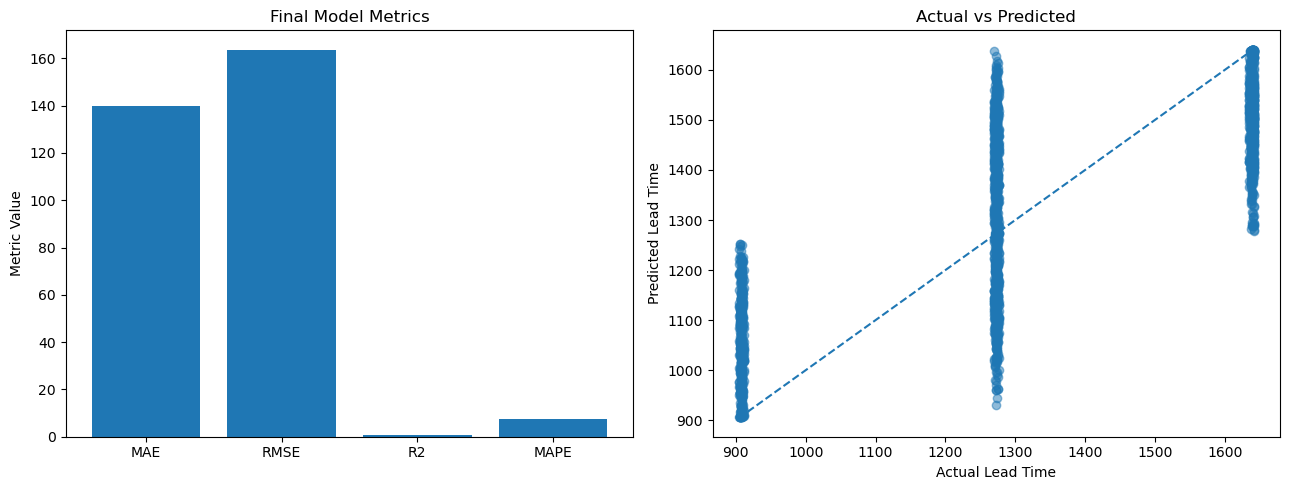

Evaluation dashboard saved.


In [270]:
# Create a visual dashboard of final model evaluation metrics

dashboard_metrics = pd.DataFrame([
    {
        "Metric": "MAE",
        "Value": mean_absolute_error(y_test, test_predictions)
    },
    {
        "Metric": "RMSE",
        "Value": np.sqrt(
            mean_squared_error(y_test, test_predictions)
        )
    },
    {
        "Metric": "R2",
        "Value": r2_score(y_test, test_predictions)
    },
    {
        "Metric": "MAPE",
        "Value": mape_value
    }
])

display(dashboard_metrics)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    dashboard_metrics["Metric"],
    dashboard_metrics["Value"]
)
axes[0].set_title("Final Model Metrics")
axes[0].set_ylabel("Metric Value")

axes[1].scatter(
    y_test,
    test_predictions,
    alpha=0.5
)

minimum_value = min(
    y_test.min(),
    test_predictions.min()
)

maximum_value = max(
    y_test.max(),
    test_predictions.max()
)

axes[1].plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

axes[1].set_xlabel("Actual Lead Time")
axes[1].set_ylabel("Predicted Lead Time")
axes[1].set_title("Actual vs Predicted")

plt.tight_layout()

plt.savefig(
    FIGURE_FOLDER / "ML_Final_Evaluation_Dashboard.png",
    dpi=300
)

plt.show()
plt.close()

print("Evaluation dashboard saved.")

In [272]:
#Export complete ML results and documentation
# Export machine learning results, reports, metrics, and model documentation

ML_REPORT_PATH = REPORT_FOLDER / "Nassau_Candy_ML_Analysis.xlsx"

prediction_export = pd.DataFrame({
    "Row_ID": df_ml.loc[X_test.index, "Row ID"].values,
    "Order_ID": df_ml.loc[X_test.index, "Order ID"].values,
    "Actual_Lead_Time": y_test.values,
    "Predicted_Lead_Time": test_predictions
})

prediction_export["Absolute_Error"] = np.abs(
    prediction_export["Actual_Lead_Time"] -
    prediction_export["Predicted_Lead_Time"]
)

export_tables = {
    "Model_Comparison": model_comparison,
    "Cross_Validation": cv_table,
    "Final_Model_Comparison": final_model_comparison,
    "Product_Errors": product_error_report,
    "Region_Errors": region_error_report,
    "ShipMode_Errors": shipmode_error_report,
    "Feature_Importance": feature_importance,
    "Target_Summary": target_summary,
    "Feature_Quality": feature_quality_report,
    "Split_Comparison": split_comparison,
    "LeadTime_Ranges": lead_time_range_report,
    "Overfitting": overfitting_report,
    "Prediction_Bias": bias_summary,
    "Dashboard_Metrics": dashboard_metrics,
    "Predictions": prediction_export
}

with pd.ExcelWriter(
    ML_REPORT_PATH,
    engine="openpyxl"
) as writer:

    for sheet_name, table in export_tables.items():
        table.to_excel(
            writer,
            sheet_name=sheet_name[:31],
            index=False
        )

# Export important reports separately
for report_name, table in export_tables.items():
    table.to_csv(
        PROCESSED_FOLDER / f"ML_{report_name}.csv",
        index=False
    )

# Save final model information
model_metadata = {
    "project": "Nassau Candy Distributor",
    "target_variable": TARGET,
    "selected_model": final_model_name,
    "predictor_features": feature_list,
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "test_MAE": float(mean_absolute_error(y_test, test_predictions)),
    "test_RMSE": float(
        np.sqrt(mean_squared_error(y_test, test_predictions))
    ),
    "test_R2": float(r2_score(y_test, test_predictions)),
    "model_file": MODEL_PATH.name
}

METADATA_PATH = MODEL_FOLDER / "Nassau_Lead_Time_Model_Metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=4)

print("Excel report saved:", ML_REPORT_PATH)
print("Model metadata saved:", METADATA_PATH)
print("CSV reports exported:", len(export_tables))

Excel report saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\Nassau_Candy_ML_Analysis.xlsx
Model metadata saved: C:\Users\hp\Nassau_Candy_Final_Submission\models\Nassau_Lead_Time_Model_Metadata.json
CSV reports exported: 15


In [96]:
# Select the final model using grouped cross-validation results

selection_results = cv_table[
    ["Model", "Mean_CV_RMSE"]
].copy()

tuned_result = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Mean_CV_RMSE": -tuning_search.best_score_
}])

selection_results = pd.concat(
    [selection_results, tuned_result],
    ignore_index=True
)

selection_results = selection_results.sort_values(
    "Mean_CV_RMSE"
).reset_index(drop=True)

display(selection_results)

final_model_name = selection_results.loc[0, "Model"]

final_model_candidates = {
    **models,
    "Tuned Random Forest": tuned_random_forest
}

final_model = final_model_candidates[final_model_name]

# Refit the selected model using the grouped training dataset
final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

print("Final selected model:", final_model_name)
print("Selection basis: Lowest grouped cross-validation RMSE.")
print("Final model refitted successfully.")

,Model,Mean_CV_RMSE
0,Tuned Random Forest,163.120414
1,Random Forest,163.178470
2,Gradient Boosting,170.029563
3,Linear Regression,179.851424


Final selected model: Tuned Random Forest
Selection basis: Lowest grouped cross-validation RMSE.
Final model refitted successfully.


In [274]:
#Final Phase 05 integrity verification
# Verify machine learning outputs and original dataset integrity

ORIGINAL_PATH = (
    PROJECT_ROOT / "data" / "raw"
    / "Nassau Candy Distributor.csv"
)

original_df = pd.read_csv(ORIGINAL_PATH)
processed_df = pd.read_csv(INPUT_PATH)

integrity_results = {
    "Original CSV exists": ORIGINAL_PATH.exists(),
    "Feature-engineered dataset exists": INPUT_PATH.exists(),
    "Original row count preserved": len(original_df) == len(df_ml),
    "All original columns retained": all(
        col in df_ml.columns for col in expected_original_columns
    ),
    "No ML rows removed": len(X) == len(df_ml),
    "Saved model exists": MODEL_PATH.exists(),
    "Excel report exists": ML_REPORT_PATH.exists(),
    "Model metadata exists": METADATA_PATH.exists()
}

# Compare original CSV values with the original columns in the
# feature-engineered dataset
try:
    pd.testing.assert_frame_equal(
        original_df[expected_original_columns],
        processed_df[expected_original_columns],
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )
    integrity_results["Original column values unchanged"] = True

except AssertionError as error:
    integrity_results["Original column values unchanged"] = False
    print("Original data comparison error:", error)

integrity_table = pd.DataFrame({
    "Integrity_Check": list(integrity_results.keys()),
    "Result": list(integrity_results.values())
})

display(integrity_table)

all_checks_passed = all(integrity_results.values())

print("\nAll integrity checks passed:", all_checks_passed)

assert all_checks_passed, "One or more integrity checks failed."

print("\nSUCCESS:  integrity verification completed.")

,Integrity_Check,Result
0,Original CSV exists,True
1,Feature-engineered dataset exists,True
2,Original row count preserved,True
3,All original columns retained,True
4,No ML rows removed,True
5,Saved model exists,True
6,Excel report exists,True
7,Model metadata exists,True
8,Original column values unchanged,True



All integrity checks passed: True

SUCCESS:  integrity verification completed.


In [102]:
# Verify machine learning outputs and original dataset integrity

ORIGINAL_PATH = (
    PROJECT_ROOT / "data" / "raw"
    / "Nassau Candy Distributor.csv"
)

original_df = pd.read_csv(ORIGINAL_PATH)
processed_df = pd.read_csv(INPUT_PATH)

integrity_results = {
    "Original CSV exists": ORIGINAL_PATH.exists(),
    "Feature-engineered dataset exists": INPUT_PATH.exists(),
    "Original row count preserved in ML dataset": (
        len(original_df) == len(df_ml)
    ),
    "Original row count preserved in processed dataset": (
        len(original_df) == len(processed_df)
    ),
    "All original columns retained": all(
        col in df_ml.columns for col in expected_original_columns
    ),
    "No ML rows removed": len(X) == len(df_ml),
    "Saved model exists": MODEL_PATH.exists(),
    "Excel report exists": ML_REPORT_PATH.exists(),
    "Model metadata exists": METADATA_PATH.exists()
}

# Compare original CSV values with the original columns
# in the feature-engineered dataset
try:
    pd.testing.assert_frame_equal(
        original_df[expected_original_columns],
        processed_df[expected_original_columns],
        check_dtype=False,
        check_exact=False,
        rtol=1e-12,
        atol=1e-12
    )
    integrity_results["Original column values unchanged"] = True

except AssertionError as error:
    integrity_results["Original column values unchanged"] = False
    print("Original data comparison error:", error)

integrity_table = pd.DataFrame({
    "Integrity_Check": list(integrity_results.keys()),
    "Result": list(integrity_results.values())
})

display(integrity_table)

all_checks_passed = all(integrity_results.values())

print("\nAll integrity checks passed:", all_checks_passed)

assert all_checks_passed, (
    "One or more integrity checks failed. "
    "Review the integrity table above."
)

print("\nSUCCESS:  integrity verification completed.")

,Integrity_Check,Result
0,Original CSV exists,True
1,Feature-engineered dataset exists,True
2,Original row count preserved in ML dataset,True
3,Original row count preserved in processed dataset,True
4,All original columns retained,True
5,No ML rows removed,True
6,Saved model exists,True
7,Excel report exists,True
8,Model metadata exists,True
9,Original column values unchanged,True



All integrity checks passed: True

SUCCESS:  integrity verification completed.


In [6]:
required_variables = [
    "models",
    "tuned_random_forest",
    "tuning_search",
    "cv_table",
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "final_model",
    "final_model_candidates"
]

print("MODEL CORRECTION READINESS CHECK")
print("-" * 40)

for variable in required_variables:
    status = "AVAILABLE" if variable in globals() else "MISSING"
    print(f"{variable}: {status}")

print("-" * 40)

MODEL CORRECTION READINESS CHECK
----------------------------------------
models: MISSING
tuned_random_forest: MISSING
tuning_search: MISSING
cv_table: MISSING
X_train: MISSING
y_train: MISSING
X_test: MISSING
y_test: MISSING
final_model: MISSING
final_model_candidates: MISSING
----------------------------------------


In [8]:
print("AVAILABLE MODEL-RELATED VARIABLES")
print("-" * 50)

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "model", "train", "test", "predict", "target",
        "feature", "random", "forest", "tuning", "cv"
    ]):
        value = globals()[name]
        print(f"{name}  |  {type(value).__name__}")

print("-" * 50)

AVAILABLE MODEL-RELATED VARIABLES
--------------------------------------------------
ElasticNetCV  |  LazyImport
GridSearchCV  |  LazyImport
LassoCV  |  LazyImport
PolynomialFeatures  |  LazyImport
RandomForestClassifier  |  LazyImport
RandomForestRegressor  |  LazyImport
RandomizedSearchCV  |  LazyImport
RidgeCV  |  LazyImport
cv2  |  LazyImport
pyforest  |  module
random  |  LazyImport
train_test_split  |  LazyImport
--------------------------------------------------


In [10]:
ip = get_ipython()

print("RECENT NOTEBOOK EXECUTION HISTORY")
print("-" * 60)

for i, code in enumerate(ip.history_manager.input_hist_raw[-30:]):
    if code.strip():
        print(f"\n--- History entry {i} ---")
        print(code[:500])

print("\n" + "-" * 60)

RECENT NOTEBOOK EXECUTION HISTORY
------------------------------------------------------------

--- History entry 1 ---
print("CROSS-VALIDATION VARIABLES")

for name in [
    "cv_table",
    "cv_results",
    "cv_results_df",
    "tuning_search",
    "models",
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "tuned_random_forest"
]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")

--- History entry 2 ---

import json
import getpass
import hashlib

def import_pandas_safely():
    try:
        return __import__('pandas')
    except ImportError:
        return False


__pandas = import_pandas_safely()


def is_data_frame(v: str):
    obj = eval(v)
    if  isinstance(obj, __pandas.core.frame.DataFrame) or isinstance(obj, __pandas.core.series.Series):
        return True


def dataframe_columns(var):
    df = eval(var)
    if isinstance(df, __pandas.core.series.Series):
        return [[df.name, str(

--- History entry 3 ---
#Final Phase 05 integrity ver

In [18]:
from pathlib import Path

print("CURRENT NOTEBOOK LOCATION:")
print(Path.cwd())

print("\nPROJECT ROOT:")
print(PROJECT_ROOT)

print("\nPATH CHECK:")
paths = {
    "Project folder": PROJECT_ROOT,
    "Raw data folder": PROJECT_ROOT / "data" / "raw",
    "Original CSV": PROJECT_ROOT / "data" / "raw" / "Nassau Candy Distributor.csv",
    "Notebooks folder": PROJECT_ROOT / "notebooks",
    "Processed data folder": PROJECT_ROOT / "data" / "processed",
    "Models folder": PROJECT_ROOT / "models",
    "Reports folder": PROJECT_ROOT / "reports",
}

for name, path in paths.items():
    print(f"{name}: {'EXISTS' if path.exists() else 'NOT FOUND'}")
    print(f"  {path}")

CURRENT NOTEBOOK LOCATION:
C:\Users\hp\Nassau_Candy_Final_Submission\notebooks

PROJECT ROOT:
C:\Users\hp\Nassau_Candy_Final_Submission

PATH CHECK:
Project folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission
Raw data folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\raw
Original CSV: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\raw\Nassau Candy Distributor.csv
Notebooks folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\notebooks
Processed data folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\processed
Models folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\models
Reports folder: EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\reports


In [280]:
import pandas as pd

print("DATAFRAME VARIABLES")
print("-" * 40)

for name, obj in list(globals().items()):
    obj_type = type(obj)

    if (
        obj_type.__name__ == "DataFrame"
        and obj_type.__module__.startswith("pandas")
    ):
        print(name, obj.shape)

print("-" * 40)

DATAFRAME VARIABLES
----------------------------------------
df_ml (10194, 34)
X (10194, 20)
X_train (8132, 20)
X_test (2062, 20)
product_errors (2062, 5)
region_errors (2062, 4)
shipmode_errors (2062, 4)
feature_quality_report (20, 5)
date_data (10194, 34)
X_time_train (8165, 20)
X_time_test (2029, 20)
prediction_table (2062, 4)
mae_table (3, 2)
residual_table (2062, 3)
product_error_report (11, 5)
region_error_report (4, 3)
original_df (10194, 18)
processed_df (10194, 34)
leakage_report (8, 2)
identifier_report (3, 2)
date_assessment (6, 2)
baseline_results (1, 4)
rmse_table (3, 2)
r2_table (3, 2)
model_comparison (4, 4)
cv_table (3, 4)
feature_importance (20, 3)
top_importance (15, 3)
final_model_comparison (4, 4)
overfitting_report (2, 4)
prediction_export (2062, 5)
shipmode_error_report (4, 3)
target_summary (12, 1)
extreme_target_records (0, 5)
split_comparison (2, 4)
range_error_data (2062, 4)
lead_time_range_report (5, 5)
bias_data (2062, 4)
bias_summary (2, 4)
mape_report (1, 

In [282]:
print("DATASET COLUMNS")
print("-" * 50)

for i, col in enumerate(df_ml.columns, 1):
    print(i, col)

print("\nDATASET INFORMATION")
print("Rows:", len(df_ml))
print("Columns:", len(df_ml.columns))
print("Order ID exists:", "Order ID" in df_ml.columns)
print("Lead Time column candidates:", [
    c for c in df_ml.columns if "lead" in c.lower()
])

DATASET COLUMNS
--------------------------------------------------
1 Row ID
2 Order ID
3 Order Date
4 Ship Date
5 Ship Mode
6 Customer ID
7 Country/Region
8 City
9 State/Province
10 Postal Code
11 Division
12 Region
13 Product ID
14 Product Name
15 Sales
16 Units
17 Gross Profit
18 Cost
19 Order_Date_Parsed
20 Ship_Date_Parsed
21 Lead_Time_Days
22 Order_Year
23 Order_Month
24 Order_Quarter
25 Order_Weekday
26 Ship_Year
27 Ship_Month
28 Profit_Margin_Pct
29 Sales_Per_Unit
30 Cost_Per_Unit
31 Profit_Per_Unit
32 Lead_Time_Category
33 Profit_Category
34 Sales_Category

DATASET INFORMATION
Rows: 10194
Columns: 34
Order ID exists: True
Lead Time column candidates: ['Lead_Time_Days', 'Lead_Time_Category']


In [284]:
selected_features = [
    "Ship Mode",
    "Country/Region",
    "City",
    "State/Province",
    "Division",
    "Region",
    "Product ID",
    "Product Name",
    "Units",
    "Sales",
    "Gross Profit",
    "Cost",
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_Weekday",
    "Profit_Margin_Pct",
    "Sales_Per_Unit",
    "Cost_Per_Unit",
    "Profit_Per_Unit"
]

X = df_ml[selected_features].copy()
y = df_ml["Lead_Time_Days"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Missing predictor columns:", 
      [c for c in selected_features if c not in df_ml.columns])
print("Variables restored successfully.")

Predictor shape: (10194, 20)
Target shape: (10194,)
Missing predictor columns: []
Variables restored successfully.


In [286]:
from sklearn.model_selection import GroupShuffleSplit

groups = df_ml["Order ID"].astype(str)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, test_indices = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

groups_train = groups.iloc[train_indices].copy()
groups_test = groups.iloc[test_indices].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training order groups:", groups_train.nunique())
print("Testing order groups:", groups_test.nunique())

assert set(groups_train).isdisjoint(set(groups_test))

print("SUCCESS: No Order ID group overlaps.")

Training rows: 8132
Testing rows: 2062
Training order groups: 6839
Testing order groups: 1710
SUCCESS: No Order ID group overlaps.


In [288]:
from pathlib import Path

# Project root
PROJECT_ROOT = Path(
    r"C:\Users\hp\Nassau_Candy_Final_Submission"
)

# Important project folders
paths_to_check = {
    "Project Root": PROJECT_ROOT,
    "Notebooks": PROJECT_ROOT / "notebooks",
    "Data": PROJECT_ROOT / "data",
    "Raw Data": PROJECT_ROOT / "data" / "raw",
    "Processed Data": PROJECT_ROOT / "data" / "processed",
    "Reports": PROJECT_ROOT / "reports",
    "Final Delivery": PROJECT_ROOT / "reports" / "final_delivery",
    "Models": PROJECT_ROOT / "models",
    "App Bundle": PROJECT_ROOT / "data" / "processed" / "app_bundle",
}

# Important project files
files_to_check = {
    "Lead Time Modeling Notebook":
        PROJECT_ROOT / "notebooks" / "Lead_Time_Modeling.ipynb",

    "Clean Handover ZIP":
        PROJECT_ROOT / "reports" / "final_delivery" /
        "package" / "Nassau_Candy_Final_Handover_Clean.zip",

    "Executive Presentation":
        PROJECT_ROOT / "reports" / "final_delivery" /
        "presentation" / "Nassau_Candy_Executive_Presentation.pptx",

    "Executive Summary":
        PROJECT_ROOT / "reports" / "final_delivery" /
        "executive_summary" / "executive_summary.md",

    "Validation Results":
        PROJECT_ROOT / "reports" / "final_delivery" /
        "validation" / "project_validation_results.json",

    "Streamlit Application":
        PROJECT_ROOT / "data" / "processed" /
        "app_bundle" / "app.py",
}

print("=" * 65)
print("PROJECT PATH CHECK")
print("=" * 65)

print("\nPROJECT FOLDERS")
for name, path in paths_to_check.items():
    print(f"{name:25} : {'EXISTS' if path.exists() else 'MISSING'}")
    print(f"  {path}")

print("\nPROJECT FILES")
for name, path in files_to_check.items():
    print(f"{name:25} : {'EXISTS' if path.is_file() else 'MISSING'}")
    print(f"  {path}")

print("\n" + "=" * 65)
print("PATH CHECK COMPLETED")
print("=" * 65)

PROJECT PATH CHECK

PROJECT FOLDERS
Project Root              : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission
Notebooks                 : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\notebooks
Data                      : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data
Raw Data                  : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\raw
Processed Data            : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\processed
Reports                   : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\reports
Final Delivery            : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\reports\final_delivery
Models                    : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\models
App Bundle                : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\data\processed\app_bundle

PROJECT FILES
Lead Time Modeling Notebook : EXISTS
  C:\Users\hp\Nassau_Candy_Final_Submission\notebooks\Lead_Time_Modeling.ipynb
Clean Handover ZIP 

In [292]:
from pathlib import Path

model_files = [
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model.joblib",
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model_Metadata.json",
    PROJECT_ROOT / "data" / "processed" / "app_bundle" /
    "models" / "model_metadata.json"
]

print("SAVED MODEL FILE CHECK")
print("=" * 60)

for file in model_files:
    if file.is_file():
        print(f"EXISTS: {file.name}")
        print(f"Size: {file.stat().st_size:,} bytes")
    else:
        print(f"MISSING: {file}")

SAVED MODEL FILE CHECK
EXISTS: Nassau_Lead_Time_Model.joblib
Size: 19,729,264 bytes
EXISTS: Nassau_Lead_Time_Model_Metadata.json
Size: 864 bytes
EXISTS: model_metadata.json
Size: 862 bytes


In [294]:
import json

metadata_files = [
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model_Metadata.json",
    PROJECT_ROOT / "data" / "processed" / "app_bundle" /
    "models" / "model_metadata.json"
]

for file in metadata_files:
    print("\n" + "=" * 60)
    print(file.name)
    print("=" * 60)

    with open(file, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print(json.dumps(metadata, indent=4))


Nassau_Lead_Time_Model_Metadata.json
{
    "project": "Nassau Candy Distributor",
    "target_variable": "Lead_Time_Days",
    "selected_model": "Tuned Random Forest",
    "predictor_features": [
        "Ship Mode",
        "Country/Region",
        "City",
        "State/Province",
        "Division",
        "Region",
        "Product ID",
        "Product Name",
        "Units",
        "Sales",
        "Gross Profit",
        "Cost",
        "Order_Year",
        "Order_Month",
        "Order_Quarter",
        "Order_Weekday",
        "Profit_Margin_Pct",
        "Sales_Per_Unit",
        "Cost_Per_Unit",
        "Profit_Per_Unit"
    ],
    "training_records": 8132,
    "testing_records": 2062,
    "test_MAE": 139.67068830546108,
    "test_RMSE": 163.67542767818506,
    "test_R2": 0.6194994066678567,
    "model_file": "Nassau_Lead_Time_Model.joblib"
}

model_metadata.json
{
    "project": "Nassau Candy Distributor",
    "target_variable": "Lead_Time_Days",
    "selected_model": 

In [296]:
from pathlib import Path
from datetime import datetime

files_to_inspect = [
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model.joblib",
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model_Metadata.json",
    PROJECT_ROOT / "data" / "processed" / "app_bundle" /
    "models" / "model_metadata.json"
]

for file in files_to_inspect:
    print("\nFile:", file.name)

    if file.exists():
        info = file.stat()
        print("Modified:", datetime.fromtimestamp(info.st_mtime))
        print("Size:", info.st_size, "bytes")
    else:
        print("MISSING")


File: Nassau_Lead_Time_Model.joblib
Modified: 2026-11-02 15:44:33.307199
Size: 19729264 bytes

File: Nassau_Lead_Time_Model_Metadata.json
Modified: 2026-11-02 15:47:42.512554
Size: 864 bytes

File: model_metadata.json
Modified: 2026-10-30 18:38:47.034154
Size: 862 bytes


In [298]:
import joblib

saved_model_path = (
    PROJECT_ROOT / "models" / "Nassau_Lead_Time_Model.joblib"
)

saved_model_check = joblib.load(saved_model_path)

print("Saved model loaded successfully.")
print("Model type:", type(saved_model_check))
print("Pipeline steps:")

if hasattr(saved_model_check, "named_steps"):
    for step_name, step_object in saved_model_check.named_steps.items():
        print(step_name, ":", type(step_object).__name__)
else:
    print("No named pipeline steps found.")

Saved model loaded successfully.
Model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps:
preprocessor : ColumnTransformer
model : RandomForestRegressor


In [300]:
saved_predictions = saved_model_check.predict(X_test)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

print("SAVED MODEL PERFORMANCE")
print("-" * 50)

print("MAE:", mean_absolute_error(y_test, saved_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, saved_predictions)))
print("R2:", r2_score(y_test, saved_predictions))

SAVED MODEL PERFORMANCE
--------------------------------------------------
MAE: 139.67068830546108
RMSE: 163.67542767818506
R2: 0.6194994066678567


In [316]:


from pathlib import Path
import zipfile
import re

root = PROJECT_ROOT

files_to_check = {
    "Executive Summary": root / "reports/final_delivery/executive_summary/executive_summary.md",
    "Validation Report": root / "reports/final_delivery/validation/project_validation_results.json",
    "Main Model Metadata": root / "models/Nassau_Lead_Time_Model_Metadata.json",
    "App Model Metadata": root / "data/processed/app_bundle/models/model_metadata.json",
    "Executive PowerPoint": root / "reports/final_delivery/presentation/Nassau_Candy_Executive_Presentation.pptx",
    "Clean ZIP": root / "reports/final_delivery/package/Nassau_Candy_Final_Handover_Clean.zip"
}

terms = [
    "95.979", "120.738", "0.792948",
    "139.670", "163.675", "0.619499",
    "163.120", "179.000", "195.629"
]

print("FINAL DELIVERY METRIC CONSISTENCY CHECK")
print("=" * 75)

for label, path in files_to_check.items():
    print(f"\n{label}")
    print("-" * 75)

    if not path.exists():
        print("FILE NOT FOUND:", path)
        continue

    try:
        if path.suffix.lower() == ".pptx":
            with zipfile.ZipFile(path) as z:
                content = " ".join(
                    z.read(n).decode("utf-8", errors="ignore")
                    for n in z.namelist()
                    if n.startswith("ppt/slides/") and n.endswith(".xml")
                )
        elif path.suffix.lower() == ".zip":
            with zipfile.ZipFile(path) as z:
                pieces = []
                for n in z.namelist():
                    if n.lower().endswith((".json", ".csv", ".md", ".txt")):
                        pieces.append(z.read(n).decode("utf-8", errors="ignore"))
                    elif n.lower().endswith(".pptx"):
                        with zipfile.ZipFile(z.open(n)) as ppt:
                            pieces.extend(
                                ppt.read(p).decode("utf-8", errors="ignore")
                                for p in ppt.namelist()
                                if p.startswith("ppt/slides/") and p.endswith(".xml")
                            )
                content = " ".join(pieces)
        else:
            content = path.read_text(encoding="utf-8", errors="ignore")

        found = [term for term in terms if term in content]

        if found:
            print("Metric values found:", ", ".join(found))
        else:
            print("None of the searched metric values found.")

    except Exception as e:
        print("READ ERROR:", repr(e))

print("\nCHECK COMPLETE — NO FILES MODIFIED")

FINAL DELIVERY METRIC CONSISTENCY CHECK

Executive Summary
---------------------------------------------------------------------------
Metric values found: 95.979, 120.738, 139.670, 163.675, 179.000, 195.629

Validation Report
---------------------------------------------------------------------------
None of the searched metric values found.

Main Model Metadata
---------------------------------------------------------------------------
Metric values found: 139.670, 163.675, 0.619499

App Model Metadata
---------------------------------------------------------------------------
Metric values found: 95.979, 120.738, 0.792948

Executive PowerPoint
---------------------------------------------------------------------------
Metric values found: 95.979, 120.738, 139.670, 163.675

Clean ZIP
---------------------------------------------------------------------------
Metric values found: 95.979, 120.738, 0.792948, 139.670, 163.675, 0.619499, 179.000, 195.629

CHECK COMPLETE — NO FILES MODIFIE

In [320]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import re

root = PROJECT_ROOT

bad_values = ["95.979", "120.738", "0.792948"]
good_values = ["139.670", "163.675", "0.619499"]
diagnostic_values = ["179.000", "195.629", "-0.161945"]

summary_path = root / "reports/final_delivery/executive_summary/executive_summary.md"
ppt_path = root / "reports/final_delivery/presentation/Nassau_Candy_Executive_Presentation.pptx"
zip_path = root / "reports/final_delivery/package/Nassau_Candy_Final_Handover_Clean.zip"

print("1. EXECUTIVE SUMMARY — MATCHING LINES")
print("=" * 75)

summary_lines = summary_path.read_text(encoding="utf-8", errors="ignore").splitlines()

for i, line in enumerate(summary_lines, start=1):
    if any(v in line for v in bad_values + good_values + diagnostic_values):
        print(f"{i}: {line.strip()}")

print("\n2. POWERPOINT — SLIDE TEXT")
print("=" * 75)

with ZipFile(ppt_path) as ppt:
    slide_files = sorted(
        [n for n in ppt.namelist()
         if re.fullmatch(r"ppt/slides/slide\d+\.xml", n)],
        key=lambda x: int(re.search(r"slide(\d+)", x).group(1))
    )

    for slide_file in slide_files:
        xml = ET.fromstring(ppt.read(slide_file))
        texts = [
            node.text for node in xml.iter()
            if node.tag.endswith("}t") and node.text
        ]
        slide_text = " | ".join(texts)

        if any(v in slide_text for v in bad_values + good_values + diagnostic_values):
            print(f"\n{slide_file}:")
            print(slide_text)

print("\n3. ZIP — FILES CONTAINING THESE VALUES")
print("=" * 75)

with ZipFile(zip_path) as archive:
    for name in archive.namelist():
        if name.endswith("/"):
            continue
        try:
            raw = archive.read(name)
            content = raw.decode("utf-8", errors="ignore")
            found = [v for v in bad_values + good_values + diagnostic_values if v in content]
            if found:
                print(f"{name}: {', '.join(found)}")
        except Exception:
            continue

print("\nREAD-ONLY REVIEW COMPLETE — NO FILES MODIFIED")

1. EXECUTIVE SUMMARY — MATCHING LINES
43: - MAE: 95.9795
44: - RMSE: 120.7382
49: - MAE: 139.6707
50: - RMSE: 163.6754
54: - MAE: 179.0003
55: - RMSE: 195.6296

2. POWERPOINT — SLIDE TEXT

ppt/slides/slide8.xml:
Predictive Model Results | Selected algorithm: Tuned Random Forest Regressor. | Metadata: MAE 95.9795, RMSE 120.7382, R-squared 0.7929. | Comparison: MAE 139.6707, RMSE 163.6754, R-squared 0.6195. | Chronological holdout R-squared: -0.1619. | Metric discrepancy remains unresolved.

3. ZIP — FILES CONTAINING THESE VALUES
Nassau_Candy_Final_Submission/models/Nassau_Lead_Time_Model_Metadata.json: 95.979, 120.738, 0.792948
Nassau_Candy_Final_Submission/notebooks/Executive_Summary_Final_Delivery.ipynb: 95.979, 120.738, 139.670, 163.675, 179.000, 195.629
Nassau_Candy_Final_Submission/notebooks/KPI_Risk_Analysis.ipynb: 95.979, 120.738, 139.670, 163.675, 0.619499
Nassau_Candy_Final_Submission/notebooks/Lead_Time_Modeling.ipynb: 95.979, 120.738, 139.670, 163.675, 0.619499, 179.000, 195.